In [1]:
# ruff: noqa: T201, T203, ERA001, E402
from __future__ import annotations

import json
import logging
import os
from itertools import product
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv

while Path.cwd().name in ["notebooks", "inference"]:
    os.chdir("..")

import src.prompts.system as system_prompts
from config.config import DATA_DIR
from config.runs_vars import SUBSET_TO_DATASET_MAP
from src.evaluate import (
    get_predictions_with_gt,
    plot_usage_histograms,
    save_analysis_results,
    store_run_metrics_df,
)
from src.formatting import (
    format_predictions_run_path,
    format_storing_pathes_from_run_path,
)
from src.LLM_servers.gemini import GeminiApiServer
from src.LLM_servers.open_router import OpenRouterServer
from src.LLM_servers.openai import OpenAIServer
from src.processing import parallel_samples_process, try_load_partial_results, try_load_precomputed_oracle_pairs
from src.prompts.prompts import (
    prompt_direct_entity,
    prompt_direct_entity_ontological,
    prompt_direct_entity_with_synonyms,
    prompt_sequential_hierarchy,
    prompt_sequential_hierarchy_ontological,
    prompt_sequential_hierarchy_with_synonyms,
    prompt_uri,
)
from src.utils import expand_setups, save_run_results, save_token_usage_stats

pd.set_option("display.max_rows", None)
load_dotenv()

%load_ext autoreload
%autoreload 2

In [2]:
logging.basicConfig(
    filename="notebook_logs.log", level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s"
)
# ignore http
logging.getLogger("httpx").setLevel(logging.WARNING)
logging.getLogger("httpcore").setLevel(logging.WARNING)
LOGGER = logging.getLogger()
LOGGER.setLevel(logging.INFO)

### Run experiments


In [3]:
MAX_WORKERS = 1500
MODELS = [
    # "gemini-2.5-flash-lite",
    "gemini-2.5-flash",
    "gemini-2.5-flash-lite",
    "gemini-2.0-flash",
    "gemini-2.0-flash-lite",
    "gemini-1.5-flash",
    # "google|gemma-3-12b-it",
    # "gemini-2.5-pro"
    # "gemini-2.5-flash-lite",
    # "gpt-4.1-nano"
]  # "gpt-4o-mini", "gemini-2.5-flash-preview-04-17", "gemini-2.0-flash-lite", "gemini-1.5-flash", "gemini-2.0-flash"

DATASETS_MAP = {
    # "bioml-2024": ["omim-ordo", "snomed-ncit.pharm", "ncit-doid", "snomed-fma.body"][:0],  # "snomed-ncit.neoplas"],  # "snomed-fma.body"]],
    # "largebio": ["fma-nci", "fma-snomed"][1:],  # "snomed-nci"],  # , ],
    "anatomy": ["human-mouse"],
}
SUFFIX = "_reduced"
# from src.constants import BinaryOutputFormat, BinaryOutputFormatWithReasoning

# EXP_NAMES_MAP = {"absent": {}, "v1": few_shots}
# EXP_NAMES_MAP = {
#     "no-reasoning": BinaryOutputFormat,
#     "with-reasoning": BinaryOutputFormatWithReasoning,
# }
EXPERIMENT_TYPE = "n_few_shots"  # "few-shot", "reasoning"
EXP_NAMES_MAP = {
    f"v{version}/{n}": n
    for n in (0, 1, 2, 3, 5, 8, 8, 11, 15, 20, 26, 33, 41, 50, 62, 75)[::-1]
    for version in range(5, 10)
}

onto_src, onto_tgt = None, None

PROMPT_FUNCTIONS_MAP = {
    prompt_function.__name__.replace("prompt_", ""): prompt_function
    for prompt_function in [
        prompt_direct_entity,
        prompt_direct_entity_ontological,
        prompt_direct_entity_with_synonyms,
        prompt_sequential_hierarchy,
        prompt_sequential_hierarchy_ontological,
        prompt_sequential_hierarchy_with_synonyms,
        prompt_uri,
    ]
}

SETUPS = []
for DATASET, SUBSETS in DATASETS_MAP.items():
    for SUBSET, EXP_NAME, MODEL in product(SUBSETS, EXP_NAMES_MAP.keys(), MODELS):
        setup = {
            "subset": SUBSET,
            "model": MODEL,
            "experiment_name": EXP_NAME,
            "max_workers": MAX_WORKERS,
            "suffix": SUFFIX,
            "prompt_functions": list(PROMPT_FUNCTIONS_MAP.keys()),
            "experiment_type": EXPERIMENT_TYPE,
        }
        SETUPS.append(setup)


In [ ]:
BASE_SETUP = {
    "subset": "human-mouse",
    "max_workers": 255,
    "suffix": "_reduced",
    "experiment_type": "models-estimation",
    "prompt_functions": ["direct_entity", "direct_entity_with_synonyms"],
    "sleep_time": 0.0,
    "model_params": {"use_openrouter": True},
}

# === Frontier proprietary models ===
FRONTIER_MODELS = [
    # "anthropic|claude-opus-4.6",
    # "anthropic|claude-opus-4.7",  # NEW: updated opus (Apr 16)
    # "anthropic|claude-sonnet-4.6",
    "anthropic|claude-haiku-4.5",
    # "openai|gpt-5.4",
    # "openai|gpt-5.5",  # NEW: major GPT upgrade (Apr 24)
    "x-ai|grok-4.3",
    "x-ai|grok-4.20",  # NEW: 2M-context grok (Mar 31)
]

# === Open-weight large reasoning models ===
OPEN_WEIGHT_REASONING_LARGE = [
    "deepseek|deepseek-v3.2",
    "deepseek|deepseek-chat-v3-0324",
    "deepseek|deepseek-v4-pro",  # NEW: DeepSeek v4 Pro (Apr 24, $0.43/$0.87)
    "qwen|qwen3-235b-a22b-2507",
    "qwen|qwen3.5-122b-a10b",
    "qwen|qwen3.5-397b-a17b",  # NEW: massive 397B MoE (Feb 16)
    "qwen|qwen3.6-max-preview",  # NEW: top Qwen 3.6 (Apr 27)
    "openai|gpt-oss-120b",
    "x-ai|grok-4.1-fast",
    "z-ai|glm-5",
    "z-ai|glm-5.1",  # NEW: updated GLM (Apr 7)
    "mistralai|mistral-medium-3-5",
    "nvidia|nemotron-3-super-120b-a12b",  # NEW: large Nvidia MoE 120B (Mar 11, $0.09/$0.45)
]

# === Open-weight medium reasoning models ===
OPEN_WEIGHT_REASONING_MEDIUM = [
    "qwen|qwen3-32b",
    "qwen|qwen3.5-35b-a3b",
    "qwen|qwen3.5-flash-02-23",
    "qwen|qwen3.6-35b-a3b",  # NEW: Qwen 3.6 MoE (Apr 27, $0.15/$1.0)
    "qwen|qwen3.6-flash",  # NEW: fast Qwen 3.6 (Apr 27, $0.25/$1.5)
    "openai|gpt-oss-20b",
    "openai|gpt-5.4-mini",  # NEW: cheaper GPT-5.4 (Mar 17, $0.75/$4.5)
    "qwen|qwen3-14b",
    "deepseek|deepseek-v4-flash",  # NEW: DeepSeek v4 Flash (Apr 24, $0.14/$0.28)
    "bytedance-seed|seed-2.0-mini",
    "bytedance-seed|seed-2.0-lite",  # NEW: cheaper Seed (Mar 10, $0.25/$2.0)
    "minimax|minimax-m2.5",
    "minimax|minimax-m2.7",  # NEW: updated MiniMax (Mar 18, $0.30/$1.2)
    "nvidia|nemotron-3-nano-omni-30b-a3b-reasoning",
]

# === Open-weight models WITHOUT reasoning support ===
OPEN_WEIGHT_NO_REASONING = [
    "meta-llama|llama-4-scout",
    "meta-llama|llama-4-maverick",
    "meta-llama|llama-3.3-70b-instruct",
    "mistralai|mistral-large-2512",
    "mistralai|mistral-small-3.2-24b-instruct",
    "mistralai|mistral-small-2603",  # NEW: Mistral Small updated (Mar 16, $0.15/$0.60)
    "mistralai|ministral-14b-2512",
    "mistralai|ministral-3b-2512",
    "mistralai|mistral-nemo",
    "google|gemma-3-27b-it",
    "google|gemma-3-12b-it",
    "google|gemma-4-31b-it",  # NEW: Gemma 4 31B (Apr 2, $0.13/$0.38)
    "google|gemma-4-26b-a4b-it",  # NEW: Gemma 4 MoE 26B (Apr 3, $0.06/$0.33)
    "qwen|qwen3.5-9b",  # NEW: small cheap Qwen (Mar 10, $0.10/$0.15) | for a few pairs it take too much time
    "moonshotai|kimi-k2.6",  # NEW: Kimi K2.6 (Apr 20, $0.74/$3.49)
    "ibm-granite|granite-4.1-8b",
]

# === Models needing custom_parsing (no structured output support) ===
CUSTOM_PARSING_MODELS = [
    "amazon|nova-micro-v1",
]

# === Unstable format (custom_parsing as fallback) ===
UNSTABLE_FORMAT_MODELS = [
    "qwen|qwen3-next-80b-a3b-instruct",
]

# === Thinking budget experiments (models supporting reasoning.max_tokens) ===
THINKING_BUDGET_MODELS = [
    "deepseek|deepseek-v3.2",
    "deepseek|deepseek-v4-pro",  # NEW
    "deepseek|deepseek-v4-flash",  # NEW
    "qwen|qwen3.5-122b-a10b",
    "qwen|qwen3.5-flash-02-23",
    "qwen|qwen3.6-flash",  # NEW
    "qwen|qwen3.6-35b-a3b",  # NEW
    "bytedance-seed|seed-2.0-mini",
    "bytedance-seed|seed-2.0-lite",  # NEW
    "google|gemini-2.5-flash",
    "google|gemini-2.5-pro",
    "google|gemini-2.5-flash-lite",
]
THINKING_BUDGETS = [0, 128, 512, 1024]

# === Reasoning effort experiments (OpenAI/Anthropic/xAI-style effort levels) ===
REASONING_EFFORT_MODELS = [
    "google|gemini-3.1-flash-lite-preview",
    "anthropic|claude-sonnet-4.6",
    "openai|gpt-oss-120b",
    # "openai|gpt-5.5",  # NEW
    "x-ai|grok-4.3",
    "x-ai|grok-4.20",  # NEW
    "mistralai|mistral-medium-3-5",
]
REASONING_EFFORTS = ["low", "medium", "high"]

SETUPS = [
    # 1. Frontier proprietary — all standard, structured output
    *[{"model": model, "experiment_name": model} for model in FRONTIER_MODELS],
    # 2. Open-weight large reasoning — standard
    *[{"model": model, "experiment_name": model} for model in OPEN_WEIGHT_REASONING_LARGE],
    # 3. Open-weight medium reasoning — standard
    *[{"model": model, "experiment_name": model} for model in OPEN_WEIGHT_REASONING_MEDIUM],
    # 4. Open-weight no reasoning — standard
    *[{"model": model, "experiment_name": model} for model in OPEN_WEIGHT_NO_REASONING],
    # 5. Custom parsing models (no structured output)
    *[
        {
            "model": model,
            "experiment_name": model,
            "model_params": {"custom_parsing": True, "use_openrouter": True},
        }
        for model in CUSTOM_PARSING_MODELS
    ],
    # 6. Unstable format models (custom parsing fallback)
    *[
        {
            "model": model,
            "experiment_name": model,
            "model_params": {"custom_parsing": True, "use_openrouter": True},
        }
        for model in UNSTABLE_FORMAT_MODELS
    ],
    # 7. Thinking budget experiments
    *[
        {
            "model": model,
            "experiment_name": f"{model}&thinking_budget={budget}",
            "model_params": {"thinking_budget": budget, "use_openrouter": True},
        }
        for model in THINKING_BUDGET_MODELS
        for budget in THINKING_BUDGETS
    ],
    # 8. Reasoning effort experiments
    *[
        {
            "model": model,
            "experiment_name": f"{model}&reasoning_effort={effort}",
            "model_params": {"reasoning_effort": effort, "use_openrouter": True},
        }
        for model in REASONING_EFFORT_MODELS
        for effort in REASONING_EFFORTS
    ],
]

SETUPS = expand_setups(SETUPS, BASE_SETUP, exclude_keys=["prompt_functions"])

print(f"Total setups: {len(SETUPS)}")
for i, s in enumerate(SETUPS):
    print(f"  {i+1:>3}. {s['model']:<55} exp={s['experiment_name']}")
    LOGGER.info(f"Prepared setup {i+1}/{len(SETUPS)}: {s['model']} - {s['experiment_name']}")

Total setups: 114
    1. anthropic|claude-haiku-4.5                              exp=anthropic|claude-haiku-4.5
    2. x-ai|grok-4.3                                           exp=x-ai|grok-4.3
    3. x-ai|grok-4.20                                          exp=x-ai|grok-4.20
    4. deepseek|deepseek-v3.2                                  exp=deepseek|deepseek-v3.2
    5. deepseek|deepseek-chat-v3-0324                          exp=deepseek|deepseek-chat-v3-0324
    6. deepseek|deepseek-v4-pro                                exp=deepseek|deepseek-v4-pro
    7. qwen|qwen3-235b-a22b-2507                               exp=qwen|qwen3-235b-a22b-2507
    8. qwen|qwen3.5-122b-a10b                                  exp=qwen|qwen3.5-122b-a10b
    9. qwen|qwen3.5-397b-a17b                                  exp=qwen|qwen3.5-397b-a17b
   10. qwen|qwen3.6-max-preview                                exp=qwen|qwen3.6-max-preview
   11. openai|gpt-oss-120b                                     exp=openai|gpt-os

In [5]:
for setup in SETUPS[:]:
    SUBSET = setup["subset"]
    DATASET = SUBSET_TO_DATASET_MAP[SUBSET]
    MODEL = setup["model"]
    EXP_NAME = setup["experiment_name"]
    MAX_WORKERS = setup["max_workers"]
    SUFFIX = setup["suffix"]
    EXPERIMENT_TYPE = setup["experiment_type"]

    setup["model_params"] = {
        **setup.get("model_params", {}),
        **({p.split("=")[0]: p.split("=")[1] for p in EXP_NAME.split("&") if "=" in p} if ("=" in EXP_NAME) else {}),
    }
    print(setup["model_params"])

    PROMPT_FUNCTIONS = {name: PROMPT_FUNCTIONS_MAP[name] for name in setup["prompt_functions"]}

    llm_oracle = (
        GeminiApiServer(**setup.get("model_params", {}))
        if MODEL.startswith("gemini") and not setup.get("model_params", {}).get("use_openrouter", False)
        else OpenRouterServer(
            max_tokens=3000, api_key=os.getenv("OPENROUTER_COST_ESTIMATION"), **setup.get("model_params", {})
        )
    )

    llm_oracle.add_system_context(system_prompts.BASELINE_INITIALIZATION_MESSAGE)

    run_path = format_predictions_run_path(DATASET, SUBSET, MODEL, EXPERIMENT_TYPE, exp_spec=EXP_NAME)
    if EXPERIMENT_TYPE == "n_few_shots":
        version, n_few_shots = EXP_NAME.split("/")
        n_few_shots = int(n_few_shots)

        few_shot_samples_path = DATA_DIR / f"preparation/{DATASET}/{SUBSET}/{version}.json"
        few_shots = json.load(few_shot_samples_path.open())["OpenAI"]

    print(MODEL, SUBSET, EXP_NAME)

    for prompt_name, prompt_function in PROMPT_FUNCTIONS.items():
        if EXPERIMENT_TYPE == "n_few_shots":
            llm_oracle.clear_context()
            llm_oracle.add_system_context(system_prompts.BASELINE_INITIALIZATION_MESSAGE)

            for sample in few_shots[prompt_function.__name__][: 2 * n_few_shots]:
                llm_oracle.add_context(sample["input"], "user")
                llm_oracle.add_context(sample["output"], "assistant")

        prediction_path, stats_path, diagram_path = format_storing_pathes_from_run_path(
            run_path, SUBSET, MODEL, prompt_name, suffix=SUFFIX
        )
        oracle_candidate_pairs = try_load_precomputed_oracle_pairs(DATASET, SUBSET, prompt_function, suffix=SUFFIX)
        partial_results = try_load_partial_results(prediction_path)

        results, tokens_usage, confidences = parallel_samples_process(
            oracle_candidate_pairs,
            llm_oracle,
            onto_src=None,
            onto_tgt=None,
            model=MODEL,
            max_workers=MAX_WORKERS,
            prompt_function=prompt_function,
            partial_results=partial_results,
            sleep_time=setup.get("sleep_time", 0.0),
        )

        save_run_results(results, prediction_path)
        plot_usage_histograms(tokens_usage, confidences, do_plot=False, do_print=False, suptitle=prompt_name)

        token_usage_path = run_path / f"{SUBSET}_{MODEL}_{prompt_name}_token_usage{SUFFIX}.csv"
        token_stats = save_token_usage_stats(tokens_usage, token_usage_path, predictions_path=prediction_path)
        print(
            f"  {prompt_name}: {token_stats['total_input_tokens']:,} in / {token_stats['total_output_tokens']:,} out tokens"
        )

        try:
            predictions = get_predictions_with_gt(run_path, DATASET, SUBSET, MODEL, prompt_name, suffix=SUFFIX)
            save_analysis_results(
                predictions,
                print_results=False,
                plot_confusion_matrix=False,
                subtitle=f"{SUBSET}: {MODEL} {prompt_name} | ",
                cm_save_path=diagram_path,
                stats_path=stats_path,
            )
        except Exception as e:
            print(f"Error: {e}")

    store_run_metrics_df(PROMPT_FUNCTIONS, run_path, DATASET, SUBSET, MODEL, suffix=SUFFIX)

{'use_openrouter': True}
anthropic|claude-haiku-4.5 human-mouse anthropic|claude-haiku-4.5


Processing Lines prompt_direct_entity: 0it [00:00, ?it/s]

  direct_entity: 70,395 in / 2,032 out tokens



Processing Lines prompt_direct_entity_with_synonyms: 0it [00:00, ?it/s]


  direct_entity_with_synonyms: 78,131 in / 2,032 out tokens
{'use_openrouter': True}
x-ai|grok-4.3 human-mouse x-ai|grok-4.3


...

  direct_entity_with_synonyms: 32,753 in / 76,938 out tokens
{'reasoning_effort': 'high', 'use_openrouter': True}
mistralai|mistral-medium-3-5 human-mouse mistralai|mistral-medium-3-5&reasoning_effort=high


Processing Lines prompt_direct_entity: 0it [00:00, ?it/s]

  direct_entity: 26,191 in / 77,450 out tokens



Processing Lines prompt_direct_entity_with_synonyms: 0it [00:00, ?it/s]


  direct_entity_with_synonyms: 32,753 in / 77,517 out tokens


In [6]:
### Error Analysis

Total error records: 329

--- Error Summary ---


,level,name,category,count
0,type,rate_limit,provider_limit,10414
1,type,model_not_found,provider_config,508
2,type,model_unavailable,provider_config,39624
3,type,invalid_request_params,provider_config,2032
4,type,parse_error,model_output,1093
5,type,length_exceeded,model_output,22
6,type,unknown,unknown,12700
7,category,provider_limit,provider_limit,10414
8,category,provider_config,provider_config,42164
9,category,model_output,model_output,1115


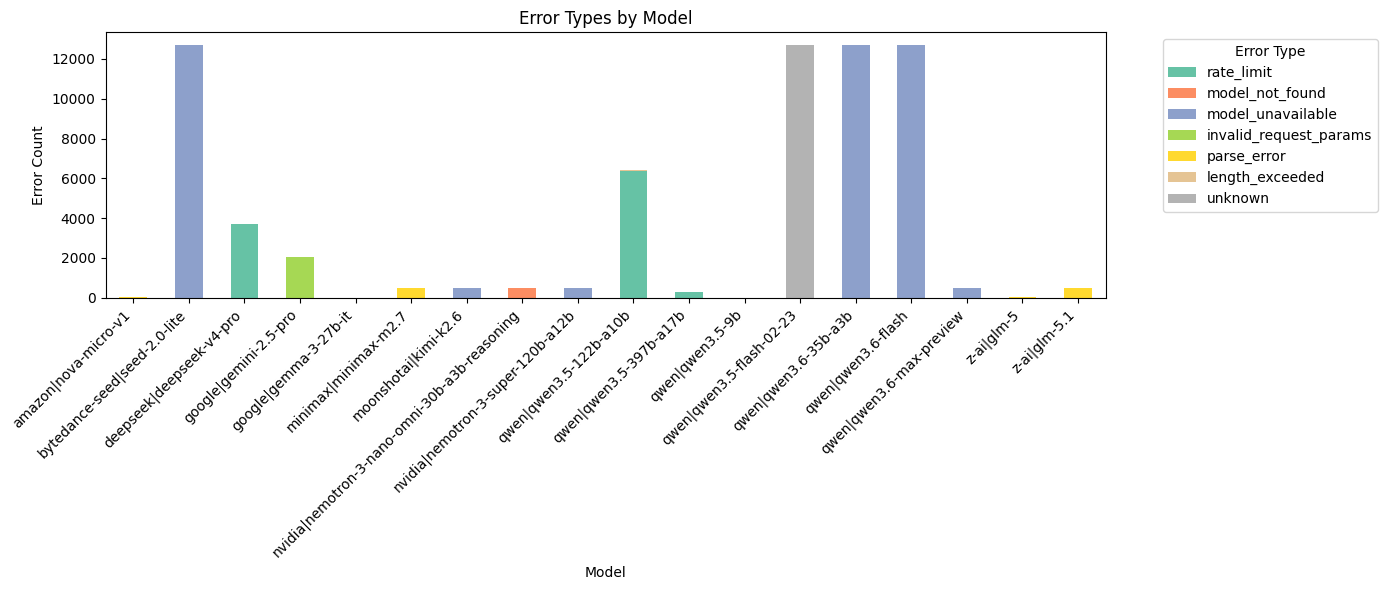

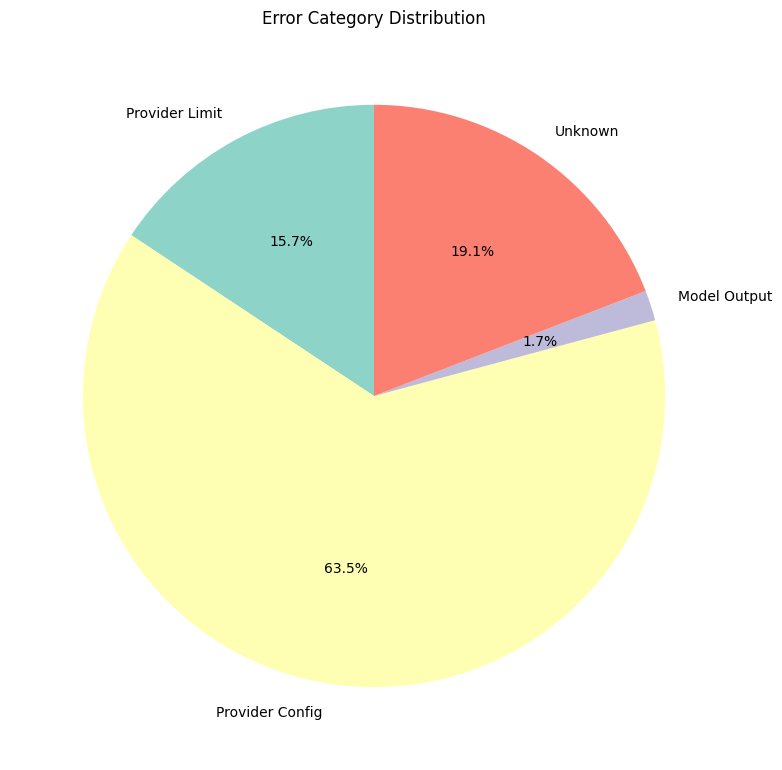

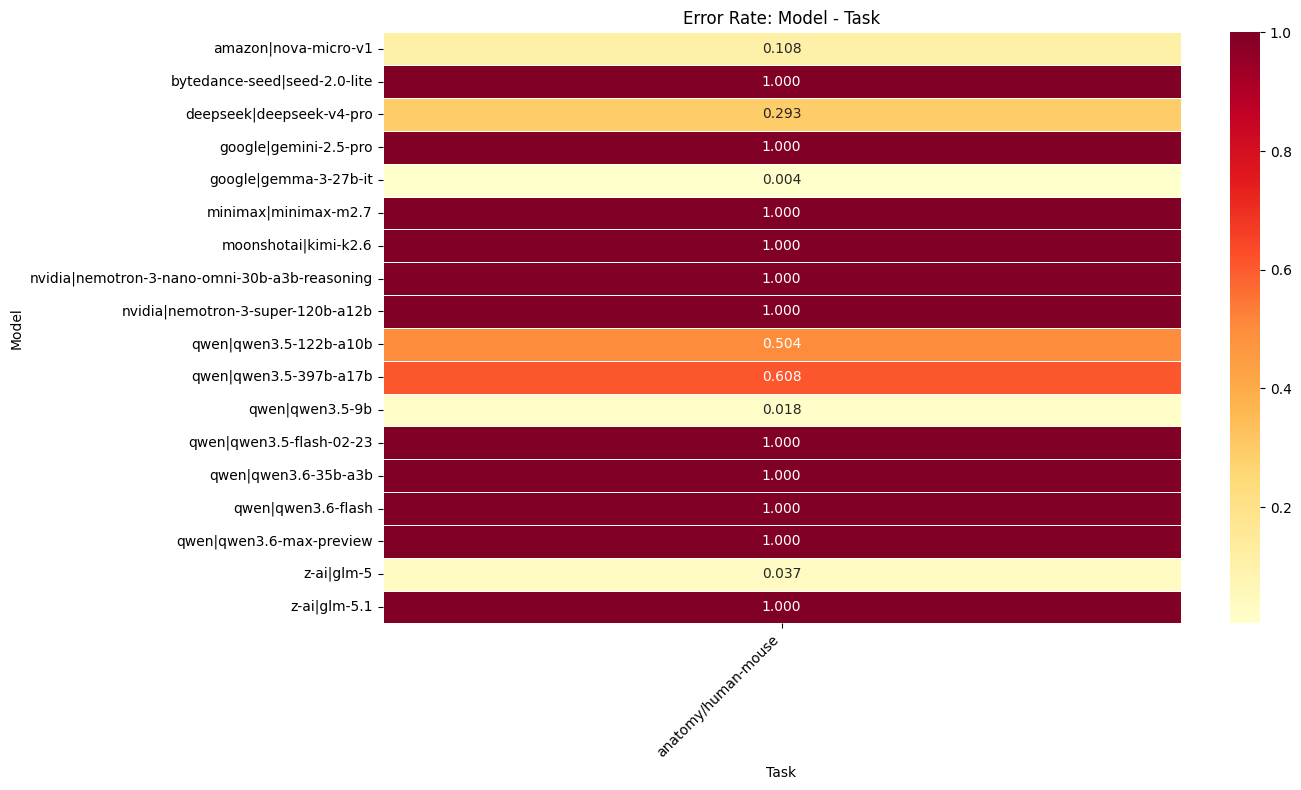

In [7]:
from src.analysis import (
    compute_error_rates,
    plot_error_breakdown,
    plot_error_category_pie,
    plot_error_rate_heatmap,
    summarize_errors,
)
from src.error_taxonomy import ErrorCategory, ErrorType

# Compute error rates across all completed experiments
error_rates_df = compute_error_rates(
    datasets_map=DATASETS_MAP,
    models=[s["model"] for s in SETUPS],
    experiment_type=BASE_SETUP["experiment_type"],
    experiments=list({s["experiment_name"] for s in SETUPS}),
)

if not error_rates_df.empty:
    print(f"Total error records: {len(error_rates_df)}")
    print(f"\n--- Error Summary ---")
    summary = summarize_errors(error_rates_df)
    display(summary)

    # Stacked bar chart: error types per model
    plot_error_breakdown(error_rates_df, group_col="Model", title="Error Types by Model")

    # Pie chart of error categories
    plot_error_category_pie(error_rates_df, title="Error Category Distribution")

    # Heatmap: error rate across Model - Task
    plot_error_rate_heatmap(error_rates_df, row_col="Model", col_col="Task", title="Error Rate: Model - Task")
else:
    print("No errors found in completed experiments.")
